# 01. State와 Node, Reducer
## 학습 목표
- `TypedDict`로 State를 정의하고 Node의 부분 업데이트를 설명한다.
- 기본 덮어쓰기와 Reducer의 리스트 누적을 비교한다.

**핵심 개념**: State는 Graph가 공유하는 현재 데이터, Node는 State를 읽고 변경할 필드만 반환하는 함수이다.  
Edge는 다음 Node를 정한다. 

## State 스키마 정의 및 이해
`greeting_node({"name": "민지", "message": "이전 인사"})`의 반환값에는 `name`이 있을까?  
Graph에 같은 입력을 주면 최종 State의 `name`은 어떻게 될까?

In [1]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

# State 정의
class MySate(TypedDict):
    name: str
    message: str

# Node 정의
def greeting_node(state: MySate) -> dict:
    return {"message": f"안녕하세요, {state['name']}님"}

# State 확인
initial = {"name": "민지", "message": "이전 인사"}
print("Python 함수 반환:", greeting_node(initial))  # 반환값에는 message만 담긴다.
print()
print("원본 딕셔너리:", initial)  # 원본은 변경되지 않고 그대로 유지된다.

Python 함수 반환: {'message': '안녕하세요, 민지님'}

원본 딕셔너리: {'name': '민지', 'message': '이전 인사'}


Python 함수는 새로운 부분 딕셔너리를 반환한다. 원본 딕셔너리를 직접 바꾸지 않는다.  
Graph는 반환된 필드만 기존 State에 반영한다.

## 그래프 설계

In [2]:
# StateGraph에 State 스키마(MyState)를 등록하여 Graph builder를 생성한다.

# SateGraph 객체 생성
builder = StateGraph(MySate)

# Node를 Graph에 등록
builder.add_node("greeting", greeting_node)

# Edge 연결(START -> greeting)
builder.add_edge(START, "greeting")

# Edge 연결(greeting -> END)
builder.add_edge("greeting", END)

# Graph 컴파일
graph = builder.compile()

## 그래프 그리기

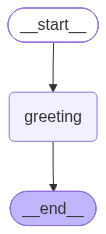

In [4]:
graph

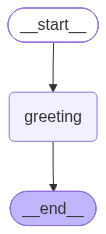

In [3]:
# Graph 그리기
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())

In [5]:
initial = {"name": "Joy", "message": "이전 인사"}

result = graph.invoke(initial)  
print("Graph 최종 State:", result)

Graph 최종 State: {'name': 'Joy', 'message': '안녕하세요, Joy님'}


In [8]:
# greeting_node가 반환한 message만 갱신되고, name은 그대로 유지되어야 한다.
assert result == {"name": "Joy", "message": "안녕하세요, Joy님"}

## Reducer: 덮어쓰기와 누적
Reducer가 없는 `status`는 새 값으로 덮어쓴다.   
`history`는 `Annotated[..., operator.add]`에 따라 새 리스트를 뒤에 붙인다. 
> Reducer는 Node들이 반환한 업데이트 값을 기존 State에 누적하거나 병합하는 역할을 한다.

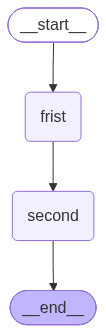

In [ ]:
from typing import Annotated
import operator

# status는 Reducer가 없어 새 값으로 덮어쓰고,
# history는 Annotated[list[str], operator.add]로 Reducer를 지정해 기존 리스트에 새 값을 누적한다.
class LogState(TypedDict):
    status: str
    history: Annotated[list[str], operator.add]

# Node 정의
def first_node(state: LogState) -> dict:
    return {"status": "첫 단계", "history": ["첫 단계"]}
# Node 정의
def second_node(state: LogState) -> dict:
    return {"status": "둘째 단계", "history": ["둘째 단계"]}

# StateGraph에 State 스키마(LogState)를 등록하여 Graph builder 생성
builder = StateGraph(LogState)

# Node를 Graph에 등록 (node에서 state의 값을 읽고, 처리하고, 업데이트)
builder.add_node("frist", first_node)
builder.add_node("second", second_node)

# Edge 연결 (실행의 흐름)
builder.add_edge(START, "frist")
builder.add_edge("frist", "second")
builder.add_edge("second", END) # END는 생략은 가능하지만 넣는게 나음

# Graph 컴파일
log_graph = builder.compile()
log_graph

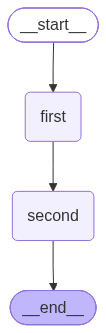

In [6]:
# Graph 그리기
from IPython.display import Image, display

# PNG 생성에 네트워크 등이 필요하면 Mermaid 텍스트로 대체한다.
try:
    display(Image(log_graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    print("PNG 시각화 불가:", type(exc).__name__)
    print(log_graph.get_graph().draw_mermaid())

In [10]:
# stream_mode="updates"는 최종 State가 아니라 각 Node가 반환한 변경분만 순서대로 보여준다.
for update in log_graph.stream({"status": "시작", "history": ["시작"]}, stream_mode="updates"):
    print("Node 업데이트:", update)

Node 업데이트: {'frist': {'status': '첫 단계', 'history': ['첫 단계']}}
Node 업데이트: {'second': {'status': '둘째 단계', 'history': ['둘째 단계']}}


In [11]:
log_result = log_graph.invoke({"status": "시작", "history": ["시작"]})

print("최종 State:", log_result)

# status는 마지막 값으로 덮어써지고, history는 시작값에 각 Node의 값이 순서대로 누적된다.
assert log_result == {"status": "둘째 단계", "history": ["시작", "첫 단계", "둘째 단계"]}

최종 State: {'status': '둘째 단계', 'history': ['시작', '첫 단계', '둘째 단계']}


`updates`는 각 Node가 반환한 변경분이다. 최종 State와 혼동하지 않는다. Reducer에 빈 리스트를 반환해도 기존 목록은 지워지지 않는다.

## 작은 수정 실습
`greeting_node`의 인사말을 "환영합니다, 이름님"으로 바꾸고 결과를 다시 예측·실행한다. 원래 코드를 유지하려면 새 함수를 만들어 같은 Graph 구성에 연결한다.

## 이해 확인
1. Node가 `{"message": "반갑습니다"}`만 반환하면 `name`은 어떻게 되는가?  
   **해설:** `name`은 그대로 유지되고 `message`만 덮어쓴다.
2. `second_node`가 `{"history": ["완료"]}`를 반환하면 기존 항목이 사라지는가?  
   **해설:** 사라지지 않는다. `operator.add`가 리스트를 이어 붙인다.

**핵심 정리:** Node는 State 전체가 아닌 업데이트를 반환하며, 필드별 Reducer가 그 업데이트의 반영 방식을 결정한다.